# Classification Bank_Data - Projet Final ML AfriAI Solutions
**Karaboué VAKABOU**

Objectif : prédire la souscription (`y=yes`) à partir de 14 caractéristiques du client et de la campagne.
Ce notebook suit l'ordre du cours : lecture, exploration, préparation, fractionnement, trois modèles,
évaluation, comparaison, test et sauvegarde. Les fonctions de préparation sont dans `bank_ml.py`,
partagées avec l'application pour reproduire exactement les transformations.

**Adaptation contre les fuites :** l'exploration est descriptive ; tous les paramètres de préparation
sont appris sur l'entraînement dans chaque pli, puis appliqués à la validation et au test.
Aucune performance antérieure du modèle Gradio n'est réutilisée. Les anciens objets ne sont pas écrasés.

## 1. Importation et lecture

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib, json, platform, warnings, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
from bank_ml import FEATURES, CATEGORICAL, NUMERIC, IQR_COLUMNS, BankPreprocessor, make_pipeline, predict
# Ne masquer que les avertissements d'affichage ; garder ceux de calcul et de version.
warnings.filterwarnings('ignore', category=FutureWarning, module='seaborn')
ROOT = Path.cwd()
assert (ROOT/'data/Bank_Data.csv').exists(), 'Ouvrir le notebook depuis Bank_Data_Streamlit.'
RESULTS = ROOT/'results'; RESULTS.mkdir(exist_ok=True)
ARTIFACTS = ROOT/'artifacts'; ARTIFACTS.mkdir(exist_ok=True)
SEED = 42
VERSIONS = {p:version(p) for p in ['scikit-learn','xgboost','pandas','numpy','joblib','matplotlib','seaborn','plotly','streamlit','reportlab']}
print('Python', platform.python_version()); display(VERSIONS)
df = pd.read_csv(ROOT/'data/Bank_Data.csv')
display(df.head()); print('Dimensions :', df.shape); df.info()
assert list(df.columns) == FEATURES + ['y']
assert set(df.y.unique()) == {'no','yes'}

Python 3.12.3


{'scikit-learn': '1.6.1',
 'xgboost': '3.4.1',
 'pandas': '3.1.1',
 'numpy': '2.5.4',
 'joblib': '1.6.0',
 'matplotlib': '3.11.2',
 'seaborn': '0.13.2',
 'plotly': '7.1.0',
 'streamlit': '1.66.1',
 'reportlab': '4.4.9'}

,age,job,marital,education,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,y
0,28,management,single,university.degree,yes,no,cellular,jun,thu,339,3,6,2,success,yes
1,55,retired,married,basic.4y,yes,no,cellular,aug,fri,137,1,3,1,success,yes
2,36,admin.,married,university.degree,no,no,cellular,jun,mon,174,1,3,1,success,yes
3,55,management,married,university.degree,no,no,cellular,aug,mon,372,3,999,0,nonexistent,yes
4,35,services,married,high.school,no,no,cellular,apr,thu,1034,2,999,0,nonexistent,yes


Dimensions : (11640, 15)
<class 'pandas.DataFrame'>
RangeIndex: 11640 entries, 0 to 11639
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          11640 non-null  int64
 1   job          11640 non-null  str  
 2   marital      11640 non-null  str  
 3   education    11640 non-null  str  
 4   housing      11640 non-null  str  
 5   loan         11640 non-null  str  
 6   contact      11640 non-null  str  
 7   month        11640 non-null  str  
 8   day_of_week  11640 non-null  str  
 9   duration     11640 non-null  int64
 10  campaign     11640 non-null  int64
 11  pdays        11640 non-null  int64
 12  previous     11640 non-null  int64
 13  poutcome     11640 non-null  str  
 14  y            11640 non-null  str  
dtypes: int64(5), str(10)
memory usage: 2.0 MB


La cible décrit une souscription, pas un défaut de crédit. La provenance exacte et la représentativité du fichier ne sont pas établies par son seul nom. `duration` suppose que le contact a déjà eu lieu : ce modèle ne convient pas au ciblage avant appel.

## 2. Exploration des données
### Variables catégorielles

,count,unique,top,freq
job,11640,12,admin.,3103
marital,11640,4,married,6853
education,11640,8,university.degree,3703
housing,11640,3,yes,6146
loan,11640,3,no,9650
contact,11640,2,cellular,8180
month,11640,10,may,3284
day_of_week,11640,5,thu,2518
poutcome,11640,3,nonexistent,9346
y,11640,2,no,7000


job : 12 modalités ; la plus fréquente est admin. (26.7%).
marital : 4 modalités ; la plus fréquente est married (58.9%).
education : 8 modalités ; la plus fréquente est university.degree (31.8%).
housing : 3 modalités ; la plus fréquente est yes (52.8%).
loan : 3 modalités ; la plus fréquente est no (82.9%).
contact : 2 modalités ; la plus fréquente est cellular (70.3%).
month : 10 modalités ; la plus fréquente est may (28.2%).
day_of_week : 5 modalités ; la plus fréquente est thu (21.6%).
poutcome : 3 modalités ; la plus fréquente est nonexistent (80.3%).
y : 2 modalités ; la plus fréquente est no (60.1%).


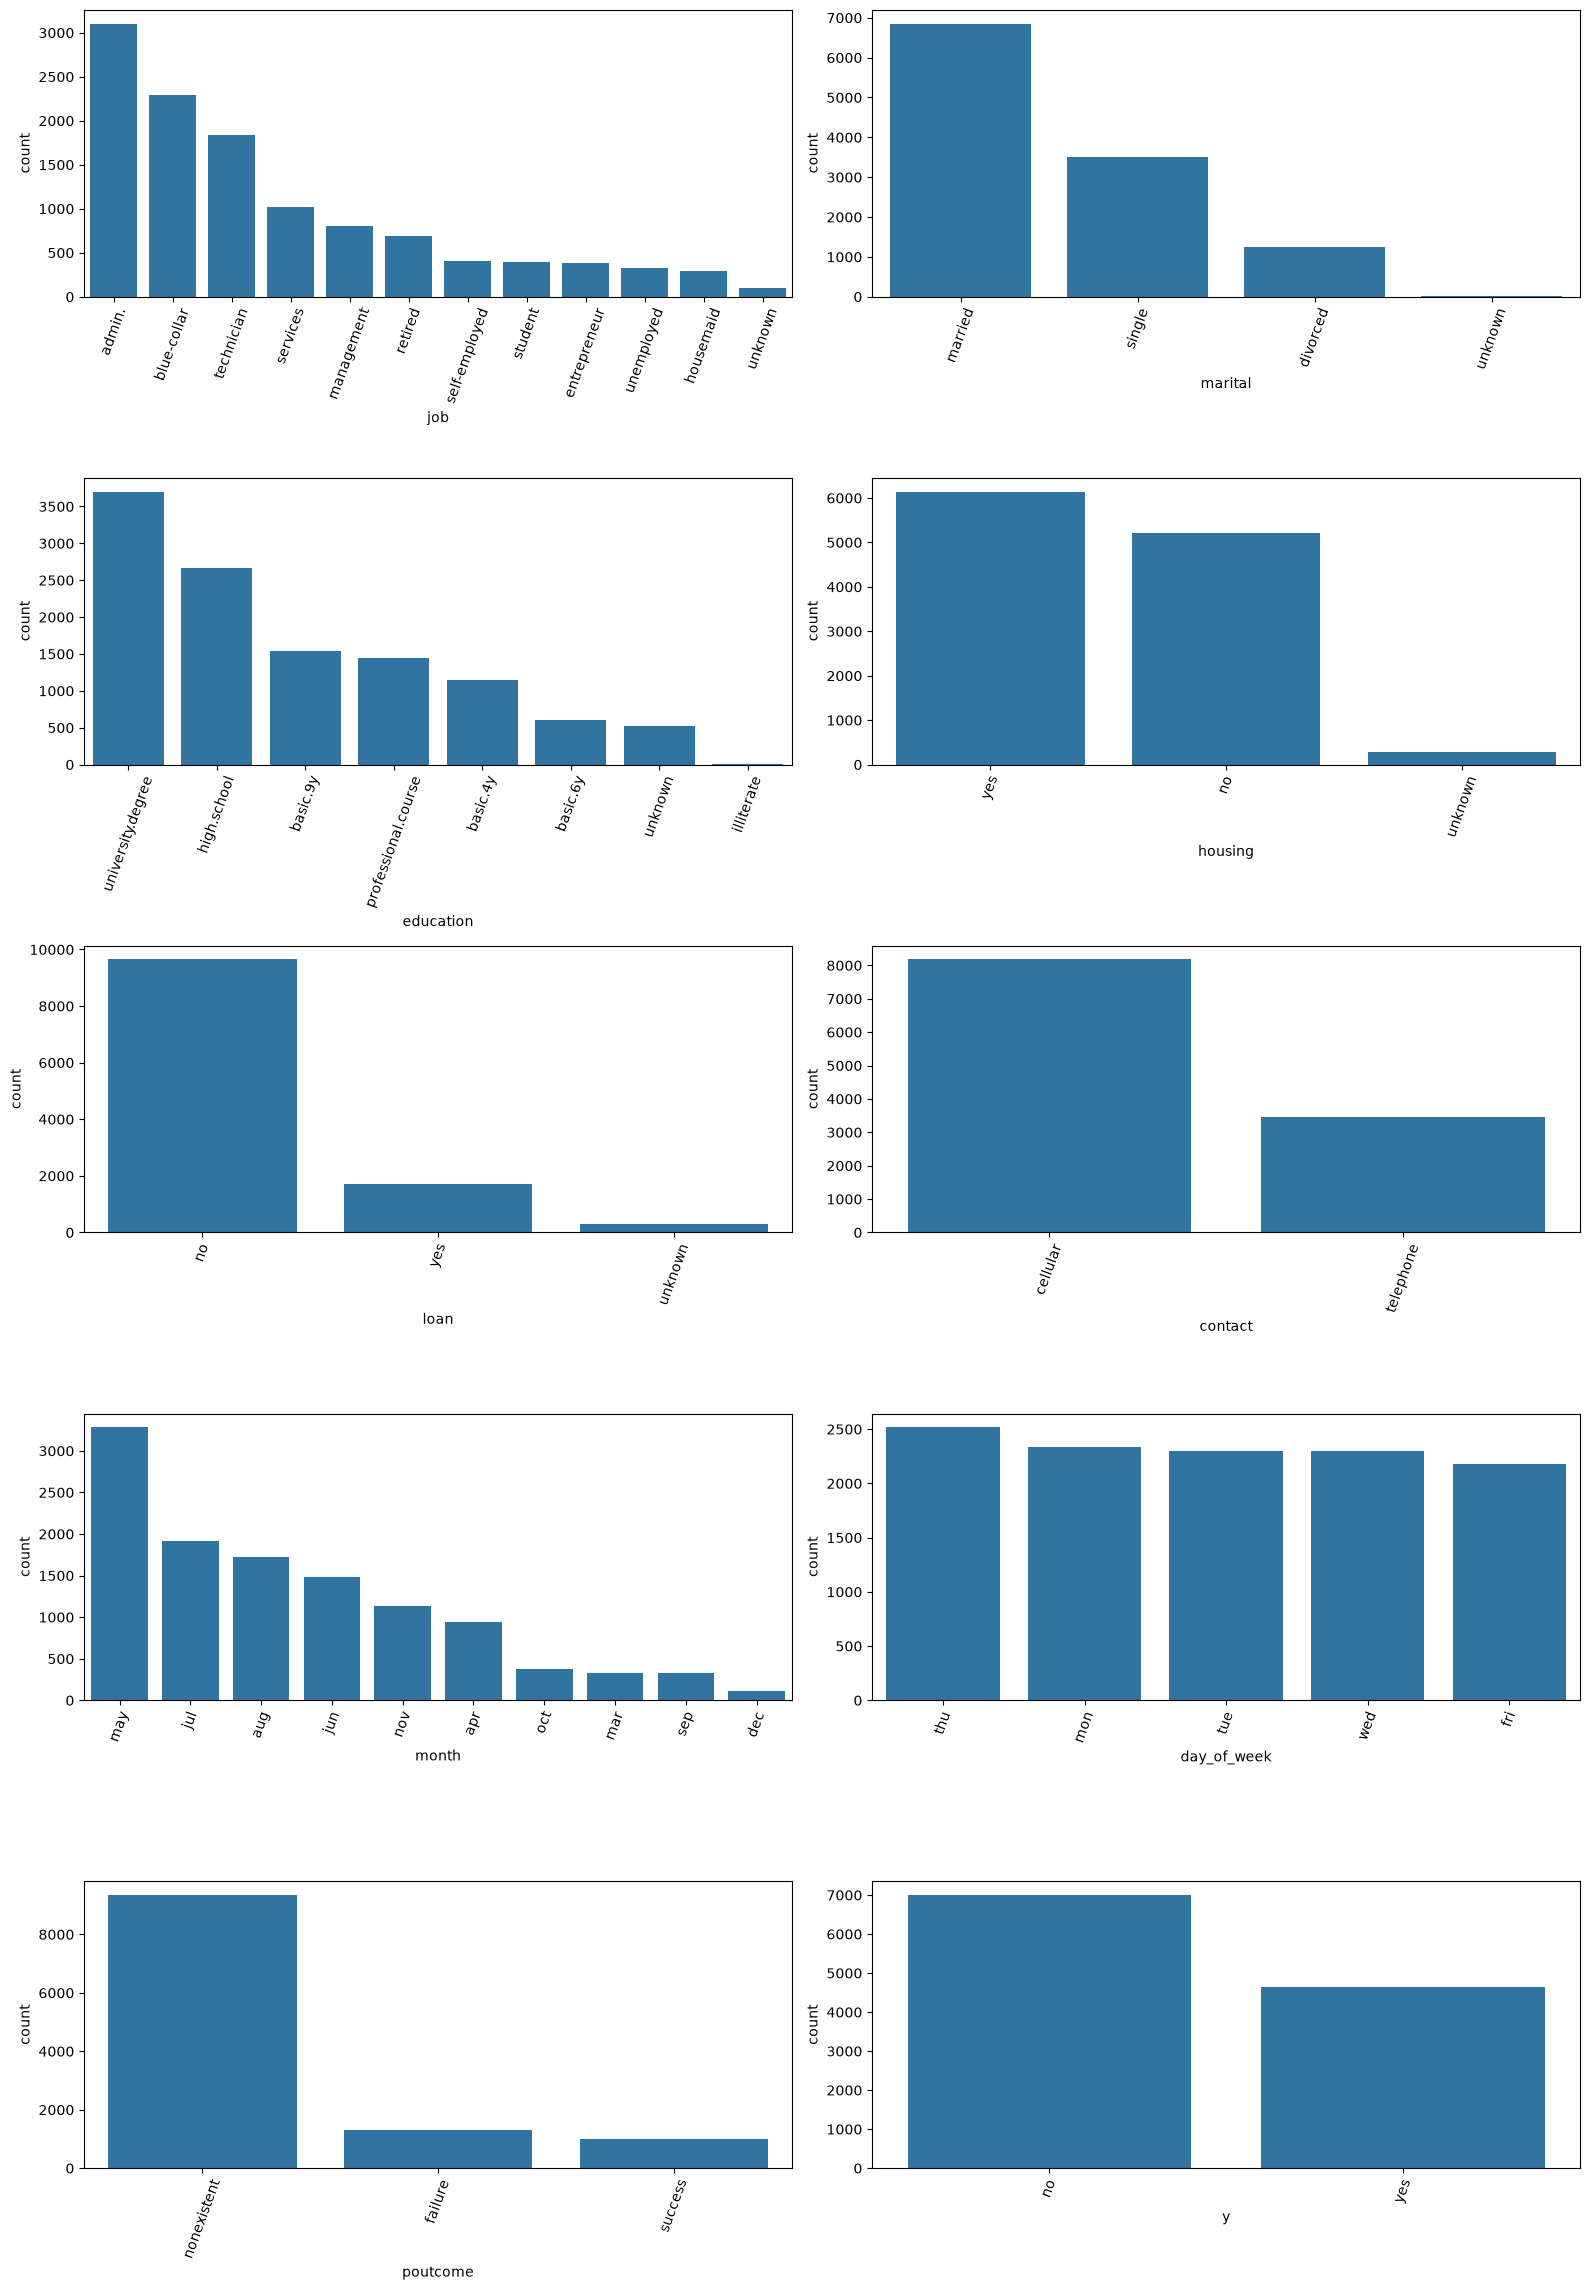

,effectif,proportion
y,,
no,7000,0.601375
yes,4640,0.398625


In [2]:
cat_data = df.select_dtypes(include=['object','string'])
display(cat_data.describe().T)
fig, axes = plt.subplots(5,2,figsize=(16,23))
for col, ax in zip(cat_data.columns, axes.flat):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.tick_params(axis='x', rotation=70)
    top = df[col].value_counts().index[0]
    print(f'{col} : {df[col].nunique()} modalités ; la plus fréquente est {top} ({df[col].eq(top).mean():.1%}).')
fig.tight_layout(); fig.savefig(RESULTS/'countplots.png',dpi=110); plt.show()
display(df.y.value_counts().to_frame('effectif').assign(proportion=df.y.value_counts(normalize=True)))

Les countplots décrivent chaque répartition ; `unknown` est une modalité explicite et sera conservée. Le déséquilibre proche de 60/40 rend l’accuracy seule insuffisante : le F1 de `yes` sera le critère principal, avec précision, rappel et ROC AUC. Aucun rééchantillonnage automatique n’est ajouté.

### Variables quantitatives

,count,mean,std,min,25%,50%,75%,max
age,11640.0,40.325515,11.639351,17.0,32.0,38.0,48.0,98.0
duration,11640.0,354.709021,341.481865,1.0,131.0,238.0,466.0,4199.0
campaign,11640.0,2.378608,2.377445,1.0,1.0,2.0,3.0,39.0
pdays,11640.0,907.797766,286.811601,0.0,999.0,999.0,999.0,999.0
previous,11640.0,0.278093,0.656532,0.0,0.0,0.0,0.0,6.0


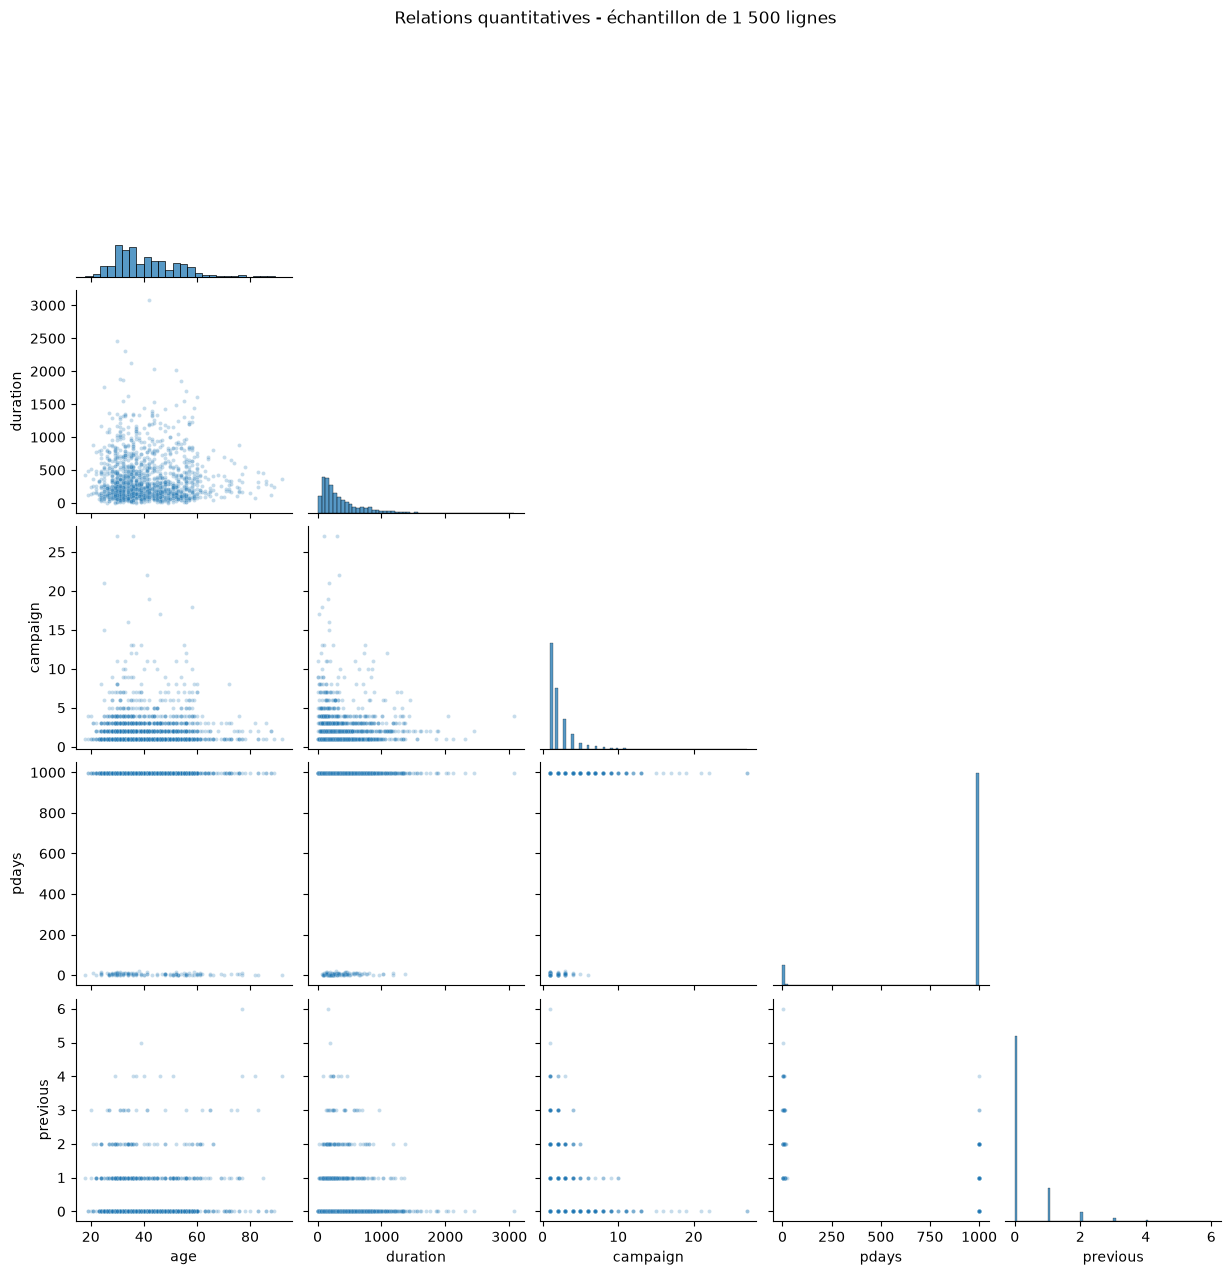

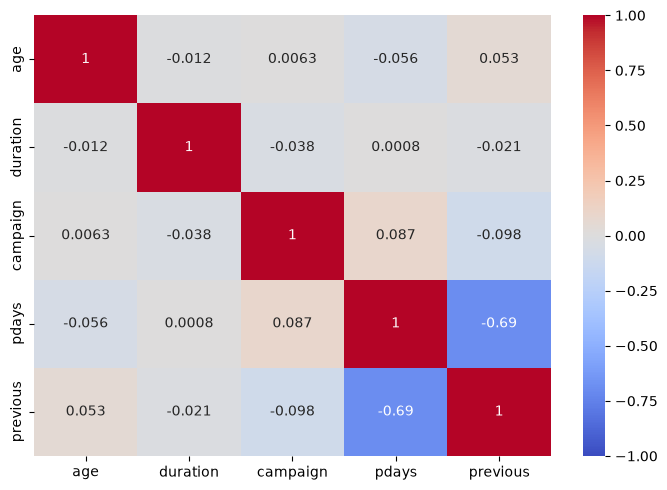

Plus forte corrélation linéaire absolue : ('pdays', 'previous') -0.693
age : médiane 38, min 17, max 98.
duration : médiane 238, min 1, max 4199.
campaign : médiane 2, min 1, max 39.
pdays : médiane 999, min 0, max 999.
previous : médiane 0, min 0, max 6.


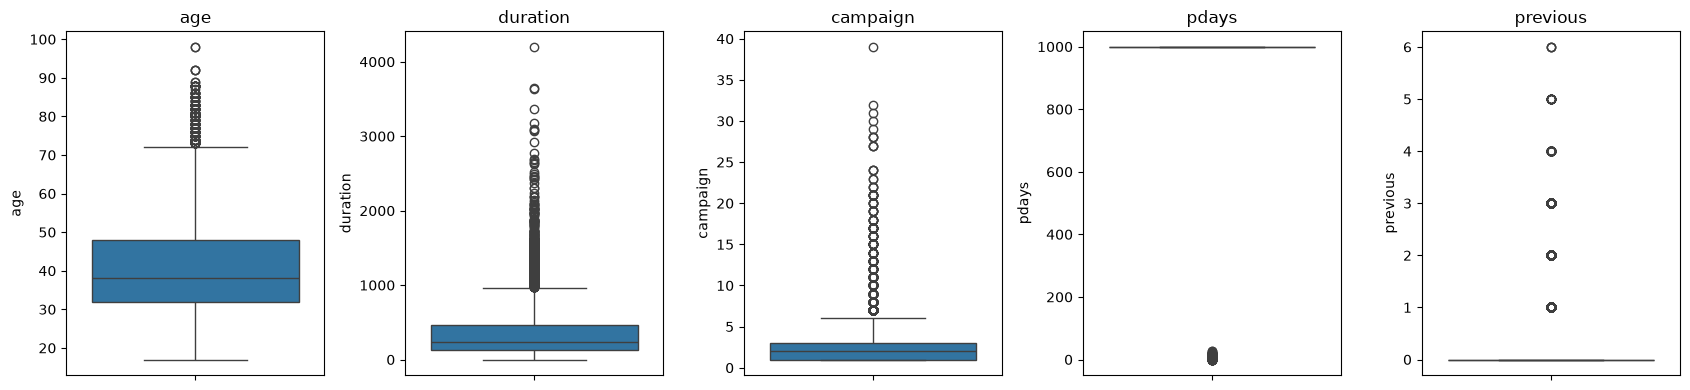

Valeurs manquantes : 0
Doublons exacts : 1


In [3]:
quant_data = df.select_dtypes(include=np.number)
display(quant_data.describe().T)
g = sns.pairplot(df[NUMERIC].sample(min(1500,len(df)),random_state=SEED), corner=True, plot_kws={'s':8,'alpha':.25})
g.fig.suptitle('Relations quantitatives - échantillon de 1 500 lignes',y=1.02)
g.savefig(RESULTS/'pairplot.png'); plt.show()
corr = quant_data.corr()
plt.figure(figsize=(7,5)); sns.heatmap(corr,annot=True,cmap='coolwarm',vmin=-1,vmax=1)
plt.tight_layout(); plt.savefig(RESULTS/'correlations.png'); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack()
if len(pairs):
    pair = pairs.abs().idxmax(); print('Plus forte corrélation linéaire absolue :',pair,round(pairs.loc[pair],3))
fig, axes = plt.subplots(1,5,figsize=(17,4))
for col, ax in zip(NUMERIC,axes):
    sns.boxplot(y=df[col],ax=ax); ax.set_title(col)
    print(f'{col} : médiane {df[col].median():g}, min {df[col].min():g}, max {df[col].max():g}.')
fig.tight_layout(); fig.savefig(RESULTS/'boxplots_bruts.png'); plt.show()
print('Valeurs manquantes :',int(df.isna().sum().sum()))
print('Doublons exacts :',int(df.duplicated().sum()))

Le pairplot est limité à 1 500 observations pour rester lisible ; les tableaux et corrélations utilisent toutes les lignes. Les nuages décrivent des associations sans causalité. La heatmap de Pearson ne mesure que les relations linéaires et `pdays=999` influence sa lecture. Les boxplots montrent les distributions longues de durée et de contacts ; une valeur hors IQR n’est pas nécessairement erronée.

## 3. Préparation des variables catégorielles
Un LabelEncoder dédié est utilisé par variable, comme dans le cours. Les modalités et encodeurs seront sauvegardés après ajustement sur l’entraînement. La cible est encodée séparément : `no=0`, `yes=1`. L’ordre numérique des catégories est une limite de cette approche. Les catégories inédites reçoivent -1 et sont signalées.

In [4]:
target_encoder = LabelEncoder().fit(['no','yes'])
print(dict(zip(target_encoder.classes_,target_encoder.transform(target_encoder.classes_))))
# Inspection uniquement, sans apprendre les transformations du futur modèle.
for col in CATEGORICAL:
    print(col, sorted(df[col].unique()))

{np.str_('no'): np.int64(0), np.str_('yes'): np.int64(1)}
job ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
marital ['divorced', 'married', 'single', 'unknown']
education ['basic.4y', 'basic.6y', 'basic.9y', 'high.school', 'illiterate', 'professional.course', 'university.degree', 'unknown']
housing ['no', 'unknown', 'yes']
loan ['no', 'unknown', 'yes']
contact ['cellular', 'telephone']
month ['apr', 'aug', 'dec', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
day_of_week ['fri', 'mon', 'thu', 'tue', 'wed']
poutcome ['failure', 'nonexistent', 'success']


## 4. Préparation des variables quantitatives
Un doublon exact est retiré pour ne pas donner deux fois le poids au même enregistrement. Les limites IQR et les voisins KNN ne seront appris que dans les plis d’entraînement. Le KNN porte sur âge, durée et nombre de contacts, avec standardisation des distances, sans cible ni codes catégoriels. `pdays=999` est préservé comme code « jamais contacté » ; `previous`, dont l’IQR est nul, reste intact. Ces adaptations évitent de détruire des informations métier. Aucune suppression supplémentaire de lignes selon les valeurs de validation/test.

In [5]:
clean = df.drop_duplicates().reset_index(drop=True)
# Toutes les caractéristiques identiques doivent rester ensemble ; ici aucun conflit de cible.
conflicts = clean.groupby(FEATURES,dropna=False)['y'].nunique().gt(1).sum()
assert conflicts == 0, 'Profils identiques à cibles différentes : adapter le fractionnement par groupes.'
assert not clean.duplicated(FEATURES).any()
print('Dimensions après retrait des doublons :',clean.shape)

Dimensions après retrait des doublons : (11639, 15)


## 5. Fractionnement et normalisation
Découpage stratifié 80/10/10, random_state=42. La standardisation est dans le pipeline, après la préparation, pour être ajustée dans chaque pli. Elle n’est jamais apprise sur la validation ou le test. Les arrondis des tailles sont ceux de train_test_split.

train 9311 part yes 0.3986
validation 1164 part yes 0.3986
test 1164 part yes 0.3986


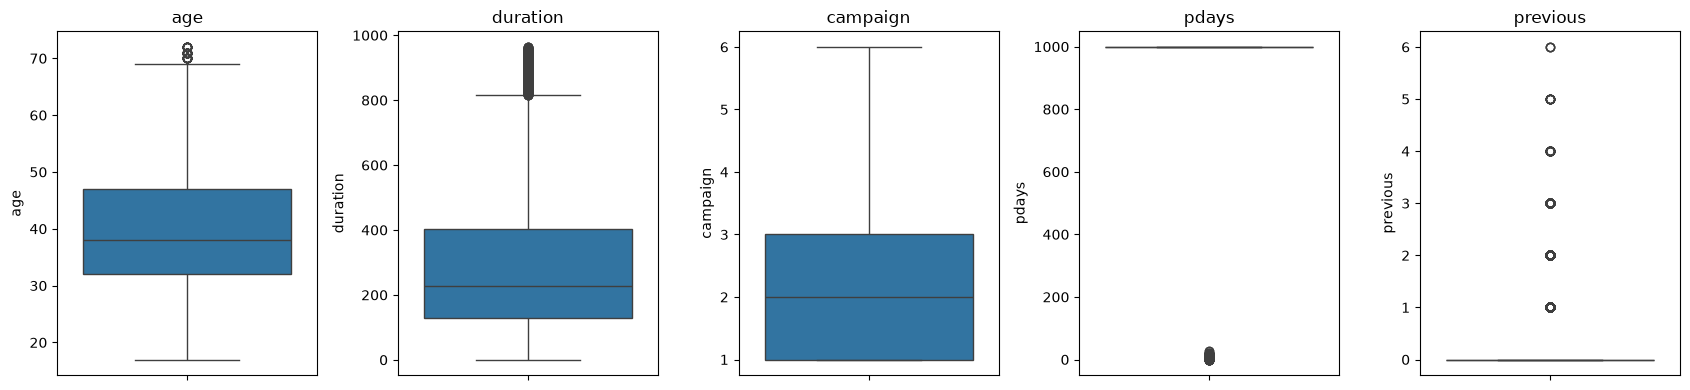

Dimensions après préparation : (9311, 14)
Lignes signalées sur train : 1098


In [6]:
x = clean[FEATURES]; y = target_encoder.transform(clean.y)
x_train,x_vt,y_train,y_vt = train_test_split(x,y,train_size=.8,random_state=SEED,stratify=y)
x_val,x_test,y_val,y_test = train_test_split(x_vt,y_vt,train_size=.5,random_state=SEED,stratify=y_vt)
for name, xx, yy in [('train',x_train,y_train),('validation',x_val,y_val),('test',x_test,y_test)]:
    print(name,len(xx),'part yes',round(float(np.mean(yy)),4))
assert not (set(x_train.index)&set(x_val.index) or set(x_train.index)&set(x_test.index) or set(x_val.index)&set(x_test.index))
split = pd.DataFrame({'index_nettoye':clean.index,'ensemble':''})
for name,xx in [('train',x_train),('validation',x_val),('test',x_test)]:
    split.loc[xx.index,'ensemble']=name
split.to_csv(RESULTS/'decoupage.csv',index=False)
# Démonstration descriptive, séparée des objets qui seront appris en CV.
preview = BankPreprocessor().fit(x_train)
prepared_train = pd.DataFrame(preview.transform(x_train),columns=FEATURES,index=x_train.index)
fig,axes=plt.subplots(1,5,figsize=(17,4))
for col,ax in zip(NUMERIC,axes):
    sns.boxplot(y=prepared_train[col],ax=ax); ax.set_title(col)
fig.tight_layout(); fig.savefig(RESULTS/'boxplots_prepares_train.png'); plt.show()
print('Dimensions après préparation :',prepared_train.shape)
print('Lignes signalées sur train :',sum(s!='Aucun' for s in preview.flags(x_train)))

Les boxplots après traitement concernent uniquement l’entraînement. Certaines valeurs peuvent rester hors IQR recalculé : l’IQR est une règle exploratoire, pas une preuve d’erreur. Nous les conservons pour éviter un filtrage répété arbitraire. Les effectifs ne changent pas après imputation.

## 6. Modélisation et fonctions d’évaluation
Pour chaque algorithme : grille explicite de quatre combinaisons, validation croisée stratifiée à cinq plis, sélection par F1 de `yes`. La grille compacte limite le temps de calcul ; ce n’est pas une recherche exhaustive. La préparation est mise en cache temporairement pour réutiliser les mêmes plis. Le critère Gradient Boosting est `friedman_mse`, et non les critères gini/entropy de Random Forest présents par erreur dans la référence.

In [7]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
models, searches, rows = {}, {}, []
cache = tempfile.TemporaryDirectory(prefix='bank_cv_')

def evaluate(name, search):
    model=search.best_estimator_; models[name]=model; searches[name]=search
    p=model.predict(x_val); prob=model.predict_proba(x_val)[:,list(model.classes_).index(1)]
    train_f1=f1_score(y_train,model.predict(x_train),zero_division=0)
    row={'modele':name,'Accuracy':accuracy_score(y_val,p),'F1':f1_score(y_val,p,zero_division=0),
         'Precision':precision_score(y_val,p,zero_division=0),'Recall':recall_score(y_val,p,zero_division=0),
         'ROC_AUC':roc_auc_score(y_val,prob),'F1_train':train_f1,'F1_CV':search.best_score_}
    row['ecart_F1_train_val']=row['F1_train']-row['F1']; rows.append(row)
    print('Paramètres optimaux :',search.best_params_); display(pd.DataFrame([row]))
    print(f'Écart F1 train - validation : {row["ecart_F1_train_val"]:.4f}. Un écart positif suggère un optimisme sur train ; ce n’est pas un test statistique.')
    fig,axes=plt.subplots(1,3,figsize=(17,4))
    ConfusionMatrixDisplay.from_predictions(y_val,p,labels=[0,1],display_labels=['Non','Oui'],ax=axes[0],colorbar=False)
    RocCurveDisplay.from_predictions(y_val,prob,pos_label=1,ax=axes[1]); axes[1].plot([0,1],[0,1],'--',color='gray')
    pd.Series(model.named_steps['model'].feature_importances_,index=FEATURES).sort_values().plot.barh(ax=axes[2])
    axes[2].set_title('Importances par impureté'); fig.suptitle(name)
    fig.tight_layout(); fig.savefig(RESULTS/(name+'_evaluation.png'),dpi=110); plt.show()
    print('Matrice : erreurs Non/Oui ; ROC : classement au fil des seuils ; importances : contributions globales, sans interprétation causale.')
    pd.DataFrame(search.cv_results_).to_csv(RESULTS/(name+'_cv.csv'),index=False)

def fit_grid(name, estimator, grid):
    search=GridSearchCV(make_pipeline(estimator,memory=cache.name),grid,scoring='f1',cv=cv,
                        n_jobs=1,error_score='raise',return_train_score=True)
    search.fit(x_train,y_train)
    evaluate(name,search)

### 6.1 Random Forest

Paramètres optimaux : {'model__max_depth': 10, 'model__n_estimators': 80}


,modele,Accuracy,F1,Precision,Recall,ROC_AUC,F1_train,F1_CV,ecart_F1_train_val
0,RandomForest,0.781787,0.714607,0.746479,0.685345,0.870074,0.802432,0.739984,0.087826


Écart F1 train - validation : 0.0878. Un écart positif suggère un optimisme sur train ; ce n’est pas un test statistique.


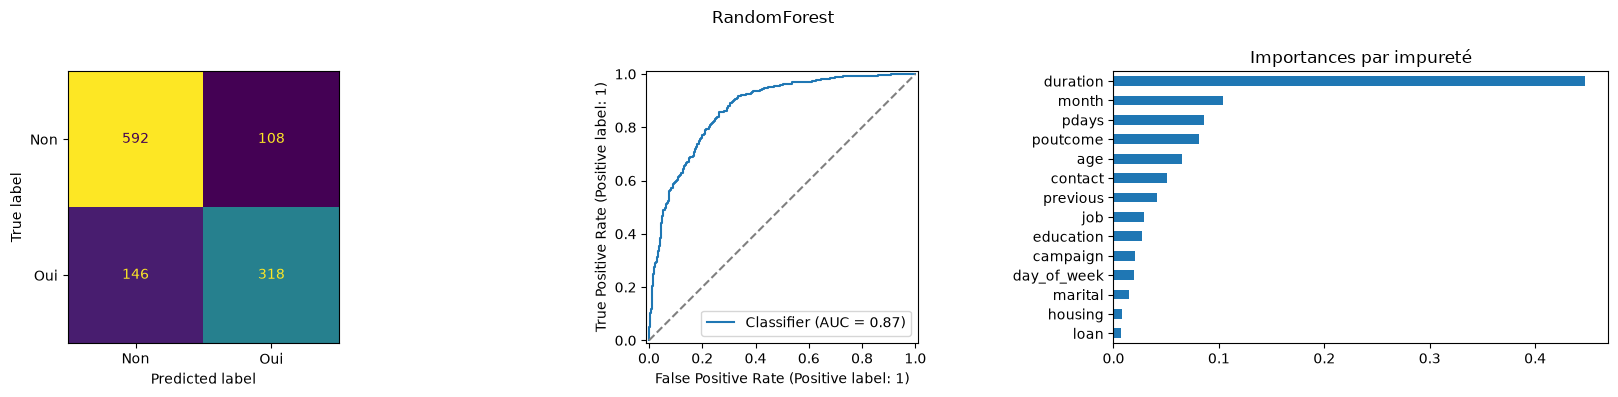

Matrice : erreurs Non/Oui ; ROC : classement au fil des seuils ; importances : contributions globales, sans interprétation causale.


In [8]:
fit_grid('RandomForest',RandomForestClassifier(random_state=SEED,n_jobs=2),
         {'model__n_estimators':[80,150],'model__max_depth':[5,10]})

### 6.2 Gradient Boosting

Paramètres optimaux : {'model__max_depth': 3, 'model__n_estimators': 150}


,modele,Accuracy,F1,Precision,Recall,ROC_AUC,F1_train,F1_CV,ecart_F1_train_val
0,GradientBoosting,0.802405,0.745575,0.765909,0.726293,0.884731,0.781886,0.767224,0.036311


Écart F1 train - validation : 0.0363. Un écart positif suggère un optimisme sur train ; ce n’est pas un test statistique.


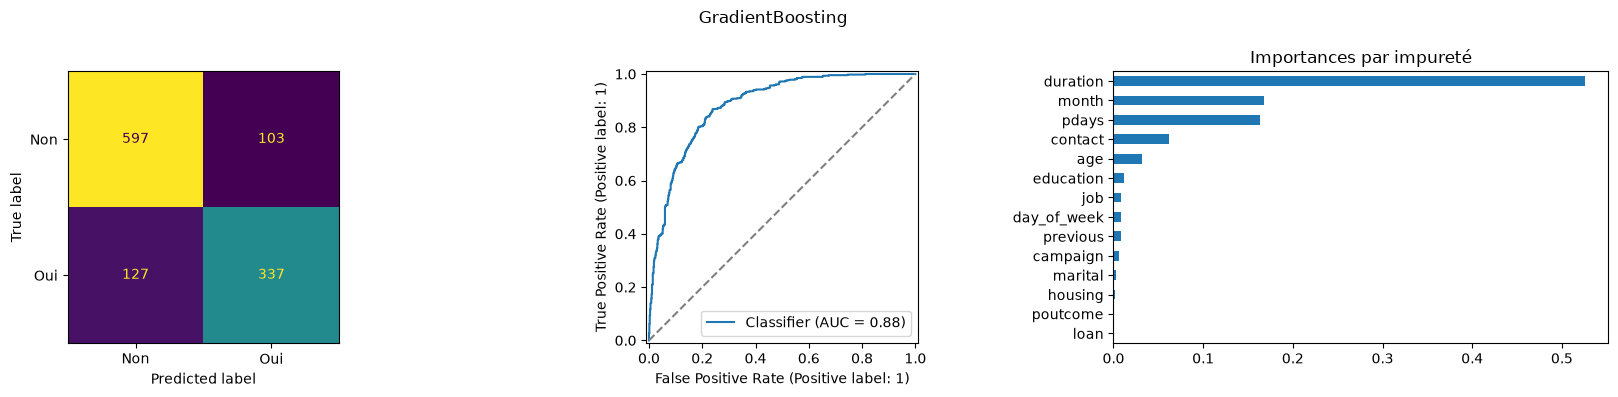

Matrice : erreurs Non/Oui ; ROC : classement au fil des seuils ; importances : contributions globales, sans interprétation causale.


In [9]:
fit_grid('GradientBoosting',GradientBoostingClassifier(random_state=SEED,criterion='friedman_mse'),
         {'model__n_estimators':[80,150],'model__max_depth':[2,3]})

### 6.3 XGBoost

Paramètres optimaux : {'model__max_depth': 4, 'model__n_estimators': 150}


,modele,Accuracy,F1,Precision,Recall,ROC_AUC,F1_train,F1_CV,ecart_F1_train_val
0,XGBoost,0.811856,0.761697,0.769231,0.75431,0.889033,0.849338,0.76434,0.08764


Écart F1 train - validation : 0.0876. Un écart positif suggère un optimisme sur train ; ce n’est pas un test statistique.


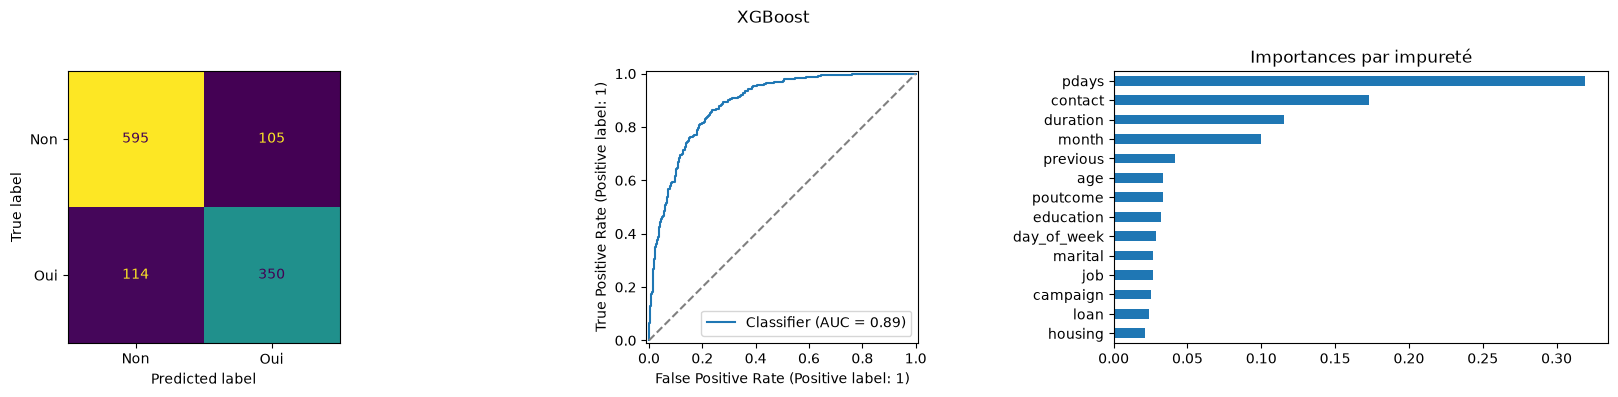

Matrice : erreurs Non/Oui ; ROC : classement au fil des seuils ; importances : contributions globales, sans interprétation causale.


In [10]:
fit_grid('XGBoost',XGBClassifier(random_state=SEED,n_jobs=2,tree_method='hist',eval_metric='logloss'),
         {'model__n_estimators':[80,150],'model__max_depth':[2,4]})

## 7. Évaluation et surapprentissage
Les matrices, ROC et importances de chaque modèle sont affichées ci-dessus avec ses métriques de validation et son F1 train. Les importances par impureté favorisent parfois les variables offrant davantage de coupures ; les probabilités ne sont pas calibrées. Le seuil de classe est celui du classifieur, sans optimisation sur le test.

## 8. Comparaison et choix du modèle

,Accuracy,F1,Precision,Recall,ROC_AUC,F1_train,F1_CV,ecart_F1_train_val
modele,,,,,,,,
RandomForest,0.781787,0.714607,0.746479,0.685345,0.870074,0.802432,0.739984,0.087826
GradientBoosting,0.802405,0.745575,0.765909,0.726293,0.884731,0.781886,0.767224,0.036311
XGBoost,0.811856,0.761697,0.769231,0.754310,0.889033,0.849338,0.764340,0.087640


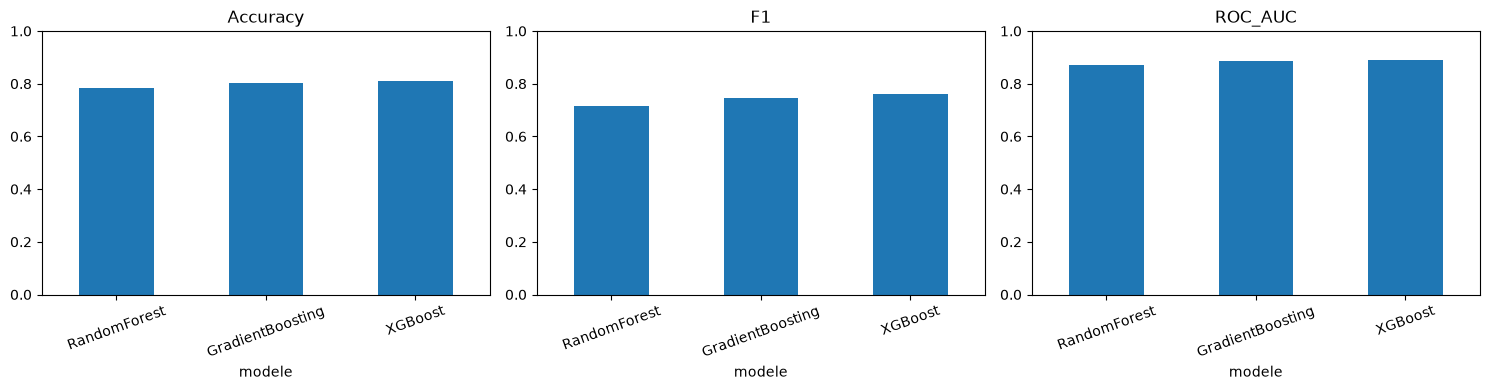

Modèle retenu : XGBoost, meilleur F1 de validation (0.7617), ROC AUC comme départage.
Le modèle reste ajusté sur train seul. Aucun réentraînement train+validation pour conserver cette évaluation et les mêmes objets.


In [11]:
comparison=pd.DataFrame(rows).set_index('modele')
display(comparison)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for metric,ax in zip(['Accuracy','F1','ROC_AUC'],axes):
    comparison[metric].plot.bar(ax=ax,rot=20,ylim=(0,1),title=metric)
fig.tight_layout(); fig.savefig(RESULTS/'comparaison.png'); plt.show()
comparison.to_csv(RESULTS/'comparaison_validation.csv')
ranking=comparison.sort_values(['F1','ROC_AUC'],ascending=False,kind='stable')
selected=ranking.index[0]; best=models[selected]
best.memory=None
print(f'Modèle retenu : {selected}, meilleur F1 de validation ({ranking.iloc[0].F1:.4f}), ROC AUC comme départage.')
print('Le modèle reste ajusté sur train seul. Aucun réentraînement train+validation pour conserver cette évaluation et les mêmes objets.')
cache.cleanup()

## 9. Test final et sauvegardes
Le test intervient après le choix et ne sert à aucun ajustement. Dix profils affichent les classes en clair ; le tableau ne remplace pas les métriques calculées sur tout le test.

Accuracy     0.831615
F1           0.781737
Precision    0.808756
Recall       0.756466
ROC_AUC      0.900536
Name: Test, dtype: float64

,age,job,marital,education,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,classe_reelle,classe_predite,probabilite_yes
3748,29,blue-collar,married,basic.9y,yes,no,cellular,may,mon,666,1,999,0,nonexistent,Oui,Oui,0.841215
4020,33,services,married,professional.course,yes,yes,cellular,jul,thu,630,4,999,0,nonexistent,Oui,Oui,0.699377
7124,40,self-employed,married,high.school,yes,no,telephone,jul,mon,46,2,999,0,nonexistent,Non,Non,0.000261
8405,37,housemaid,married,basic.4y,yes,no,cellular,aug,tue,176,1,999,0,nonexistent,Non,Non,0.187812
1930,33,unemployed,married,basic.9y,no,no,telephone,jun,wed,563,1,999,0,nonexistent,Oui,Oui,0.526799
9437,33,management,married,university.degree,yes,no,telephone,may,mon,396,9,999,0,nonexistent,Non,Non,0.230512
9090,39,blue-collar,married,basic.9y,no,no,cellular,jul,tue,181,1,999,0,nonexistent,Non,Non,0.103699
10690,34,technician,married,professional.course,no,no,cellular,apr,fri,132,2,999,1,failure,Non,Non,0.098140
6755,46,blue-collar,married,basic.4y,yes,no,telephone,may,thu,431,2,999,0,nonexistent,Non,Non,0.160135
4152,30,student,single,unknown,yes,no,cellular,mar,tue,136,1,9,1,success,Oui,Oui,0.982512


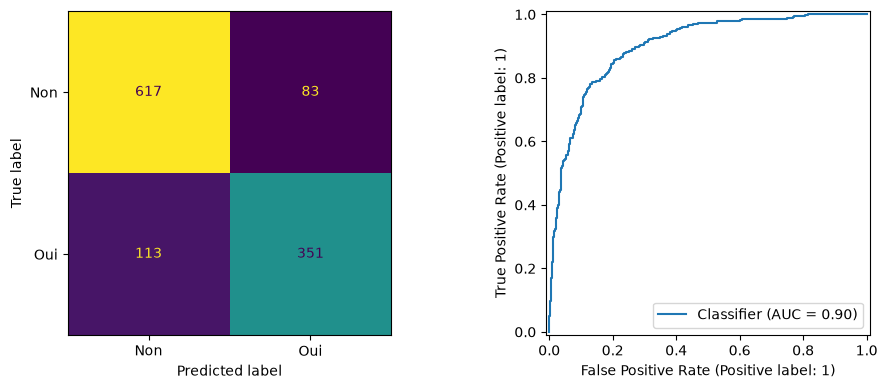

Rechargement : classes et probabilités identiques sur tout le test.


194

In [12]:
test_pred=best.predict(x_test); test_proba=best.predict_proba(x_test)[:,list(best.classes_).index(1)]
test_metrics={'Accuracy':accuracy_score(y_test,test_pred),'F1':f1_score(y_test,test_pred,zero_division=0),
              'Precision':precision_score(y_test,test_pred,zero_division=0),
              'Recall':recall_score(y_test,test_pred,zero_division=0),'ROC_AUC':roc_auc_score(y_test,test_proba)}
display(pd.Series(test_metrics,name='Test'))
ten=x_test.head(10).copy()
ten['classe_reelle']=['Oui' if z==1 else 'Non' for z in y_test[:10]]
ten['classe_predite']=['Oui' if z==1 else 'Non' for z in test_pred[:10]]
ten['probabilite_yes']=test_proba[:10]
display(ten); ten.to_csv(RESULTS/'dix_predictions_test.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['Non','Oui'],ax=axes[0],colorbar=False)
RocCurveDisplay.from_predictions(y_test,test_proba,ax=axes[1]); fig.tight_layout()
fig.savefig(RESULTS/'test_final.png'); plt.show()
# Sauvegardes nouvelles et séparées des objets historiques à la racine.
prepare=best.named_steps['prepare']; scaler=best.named_steps['scaler']; model=best.named_steps['model']
encoders=prepare.encoders_+[target_encoder]; uniques=prepare.uniques_+[target_encoder.classes_]
objects={'bank_pipeline.joblib':best,'preprocessor.joblib':prepare,'encoders.joblib':encoders,
         'uniques.joblib':uniques,'scaler.joblib':scaler,'model.joblib':model,
         'list_items.joblib':[encoders,uniques,scaler,model]}
for name,obj in objects.items(): joblib.dump(obj,ARTIFACTS/name)
reloaded=joblib.load(ARTIFACTS/'bank_pipeline.joblib')
np.testing.assert_array_equal(best.predict(x_test),reloaded.predict(x_test))
np.testing.assert_allclose(best.predict_proba(x_test),reloaded.predict_proba(x_test),rtol=0,atol=0)
ee,uu,ss,mm=joblib.load(ARTIFACTS/'list_items.joblib')
pp=joblib.load(ARTIFACTS/'preprocessor.joblib')
np.testing.assert_array_equal(mm.predict(ss.transform(pp.transform(x_test))),test_pred)
np.testing.assert_allclose(mm.predict_proba(ss.transform(pp.transform(x_test))),best.predict_proba(x_test),rtol=0,atol=0)
metadata={'created_utc':datetime.now(timezone.utc).isoformat(),'author':'Karaboué VAKABOU',
          'selected_model':selected,'python':platform.python_version(),'versions':VERSIONS,
          'data_sha256':hashlib.sha256((ROOT/'data/Bank_Data.csv').read_bytes()).hexdigest(),
          'source_sha256':{f:hashlib.sha256((ROOT/f).read_bytes()).hexdigest() for f in ['bank_ml.py','Projet_Clas_Bank_Data_VAKABOU.ipynb']},
          'raw_rows':len(df),'clean_rows':len(clean),'split':{'train':len(x_train),'validation':len(x_val),'test':len(x_test)},
          'random_state':SEED,'cv':5,'selection':'F1 validation (yes), puis ROC AUC',
          'best_params':searches[selected].best_params_,
          'validation_metrics':comparison.loc[selected].to_dict(),'test_metrics':test_metrics,
          'reload_verified':True,'features':FEATURES,
          'limitations':['duration connue après contact','Probabilités non calibrées',
          'Provenance et représentativité non établies','LabelEncoder impose un ordre artificiel',
          'Grilles compactes ; validation aléatoire, sans évaluation temporelle']}
metadata['artifact_sha256']={name:hashlib.sha256((ARTIFACTS/name).read_bytes()).hexdigest() for name in objects}
(ARTIFACTS/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
print('Rechargement : classes et probabilités identiques sur tout le test.')
# Dépendances directes figées selon cette exécution, pour le déploiement.
packages=['streamlit','pandas','numpy','scikit-learn','xgboost','joblib','reportlab','matplotlib','seaborn','plotly','ipykernel','nbformat']
(ROOT/'requirements.txt').write_text(''.join(f'{p}=={version(p)}\n' for p in packages),encoding='utf-8')


## 10. Déploiement Streamlit
L’application charge `artifacts/bank_pipeline.joblib`, jamais les anciens objets à la racine. `list_items.joblib` respecte le regroupement demandé mais exige **aussi** `preprocessor.joblib` pour reproduire IQR/KNN. Le pipeline complet est donc la voie recommandée. Le module `bank_ml.py` doit accompagner les objets. Les rapports utilisent exclusivement les métadonnées de cette exécution.

Avant publication : exécuter ce notebook dans le `.venv` local, tester l’application et les rapports, puis publier les résultats locaux. Une exécution de référence dans un autre environnement ne remplace pas ces contrôles. Ne pas utiliser ces résultats comme décision bancaire automatisée.